# 🎓📍 US College Salaries — Regional × School Type Effects (Final Project)

**Goal:** Build a *portfolio-ready* analysis that integrates **college-level salaries** with **regional context**, quantifies **uplift vs regional averages**, and tests **interaction effects** between Region and School Type.

**Why this matters (Recession Motivation):**
In an economic downturn, salary prospects for new graduates can shift meaningfully across **regions** and **institution types**.  
This project helps students and decision-makers identify schools that **consistently outperform their regional baselines**, and understand how **regional context modifies outcomes**.

**Files (place next to the notebook or update paths in Section 1):**
- `salaries-by-college-type.csv`  (college salaries + School Type)
- `salaries-by-region.csv`        (college salaries + Region)

Environment: Python 3.x, `pandas`, `numpy`, `matplotlib`, `scikit-learn`.


## 0) (Optional) Install dependencies

In [15]:
# Run only if imports fail later.
%pip install --upgrade pip
%pip install pandas numpy matplotlib scikit-learn
print("Title: Dependencies")
print("Caption: If imports fail, uncomment the %pip lines above and run this cell once.")

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Title: Dependencies
Caption: If imports fail, uncomment the %pip lines above and run this cell once.


## 1) Setup & Data Load

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Paths (edit if your files live elsewhere)
DATA_PATHS = {
    'college': Path('salaries-by-college-type.csv'),
    'region':  Path('salaries-by-region.csv'),
}

for key, p in DATA_PATHS.items():
    assert p.exists(), f"CSV not found for {key}: {p}. Place the CSV next to this notebook or update DATA_PATHS."

df_type_raw.index = range(1, len(df_type_raw) + 1)
df_region_raw.index = range(1, len(df_region_raw) + 1)

print('Title: Raw dataset previews')
print('Caption: First 5 rows from School-Type and Region datasets.')
display(df_type_raw.head())
display(df_region_raw.head())

Title: Raw dataset previews
Caption: First 5 rows from School-Type and Region datasets.


,School Name,School Type,Starting Median Salary,Mid-Career Median Salary,Mid-Career 10th Percentile Salary,Mid-Career 25th Percentile Salary,Mid-Career 75th Percentile Salary,Mid-Career 90th Percentile Salary
1,Massachusetts Institute of Technology (MIT),Engineering,"$72,200.00","$126,000.00","$76,800.00","$99,200.00","$168,000.00","$220,000.00"
2,California Institute of Technology (CIT),Engineering,"$75,500.00","$123,000.00",NaN,"$104,000.00","$161,000.00",NaN
3,Harvey Mudd College,Engineering,"$71,800.00","$122,000.00",NaN,"$96,000.00","$180,000.00",NaN
4,"Polytechnic University of New York, Brooklyn",Engineering,"$62,400.00","$114,000.00","$66,800.00","$94,300.00","$143,000.00","$190,000.00"
5,Cooper Union,Engineering,"$62,200.00","$114,000.00",NaN,"$80,200.00","$142,000.00",NaN


,School Name,Region,Starting Median Salary,Mid-Career Median Salary,Mid-Career 10th Percentile Salary,Mid-Career 25th Percentile Salary,Mid-Career 75th Percentile Salary,Mid-Career 90th Percentile Salary
1,Stanford University,California,"$70,400.00","$129,000.00","$68,400.00","$93,100.00","$184,000.00","$257,000.00"
2,California Institute of Technology (CIT),California,"$75,500.00","$123,000.00",NaN,"$104,000.00","$161,000.00",NaN
3,Harvey Mudd College,California,"$71,800.00","$122,000.00",NaN,"$96,000.00","$180,000.00",NaN
4,"University of California, Berkeley",California,"$59,900.00","$112,000.00","$59,500.00","$81,000.00","$149,000.00","$201,000.00"
5,Occidental College,California,"$51,900.00","$105,000.00",NaN,"$54,800.00","$157,000.00",NaN


## 2) Schema Check & Cleaning

In [17]:
# Make working copies
dft = df_type_raw.copy()
dfr = df_region_raw.copy()

# Standardize column names
def normalize_cols(df):
    df.columns = (df.columns
                  .str.strip()
                  .str.replace('  ', ' ', regex=False)
                  .str.replace(' ', '_', regex=False)
                  .str.replace('-', '_', regex=False))
    return df

dft = normalize_cols(dft)
dfr = normalize_cols(dfr)

print("Title: Column names after normalization")
print("Caption: Ensures consistent names for merging and analysis.")
print("Type columns:", list(dft.columns))
print("Region columns:", list(dfr.columns))

# Identify salary columns
salary_cols_t = [c for c in dft.columns if 'Salary' in c]
salary_cols_r = [c for c in dfr.columns if 'Salary' in c]
assert 'School_Name' in dft.columns, "Expected 'School_Name' in college-type CSV"
assert 'School_Name' in dfr.columns, "Expected 'School_Name' in region CSV"
assert 'Region' in dfr.columns, "Expected 'Region' in region CSV"

# Cleanup currency strings -> float
def clean_money(df, cols):
    for c in cols:
        df[c] = (df[c].astype(str)
                        .str.replace('$','', regex=False)
                        .str.replace(',','', regex=False)
                        .replace({'': np.nan, 'nan': np.nan})
                        .astype(float))
    return df

dft = clean_money(dft, salary_cols_t)
dfr = clean_money(dfr, salary_cols_r)

print('Title: Null count after cleaning')
print('Caption: Currency fields converted to floats; nulls shown below.')
display(dft.isnull().sum())
display(dfr.isnull().sum())

Title: Column names after normalization
Caption: Ensures consistent names for merging and analysis.
Type columns: ['School_Name', 'School_Type', 'Starting_Median_Salary', 'Mid_Career_Median_Salary', 'Mid_Career_10th_Percentile_Salary', 'Mid_Career_25th_Percentile_Salary', 'Mid_Career_75th_Percentile_Salary', 'Mid_Career_90th_Percentile_Salary']
Region columns: ['School_Name', 'Region', 'Starting_Median_Salary', 'Mid_Career_Median_Salary', 'Mid_Career_10th_Percentile_Salary', 'Mid_Career_25th_Percentile_Salary', 'Mid_Career_75th_Percentile_Salary', 'Mid_Career_90th_Percentile_Salary']
Title: Null count after cleaning
Caption: Currency fields converted to floats; nulls shown below.


School_Name                           0
School_Type                           0
Starting_Median_Salary                0
Mid_Career_Median_Salary              0
Mid_Career_10th_Percentile_Salary    38
Mid_Career_25th_Percentile_Salary     0
Mid_Career_75th_Percentile_Salary     0
Mid_Career_90th_Percentile_Salary    38
dtype: int64

School_Name                           0
Region                                0
Starting_Median_Salary                0
Mid_Career_Median_Salary              0
Mid_Career_10th_Percentile_Salary    47
Mid_Career_25th_Percentile_Salary     0
Mid_Career_75th_Percentile_Salary     0
Mid_Career_90th_Percentile_Salary    47
dtype: int64

## 3) Merge Region Label + Compute Region Baselines

In [27]:
# Attach Region label to college-type table
region_lookup = dfr[['School_Name', 'Region']].drop_duplicates()
df = dft.merge(region_lookup, on='School_Name', how='left')

# Compute Region-level averages (regional baselines)
region_baseline = (dfr
                   .groupby('Region')[salary_cols_r]
                   .mean()
                   .reset_index()
                   .rename(columns={c: c + '_RegionAvg' for c in salary_cols_r}))

# Merge regional baselines onto main df
df = df.merge(region_baseline, on='Region', how='left')

print('Title: Merged master table (preview)')
print('Caption: College salaries + School Type + Region + Region-level averages (_RegionAvg).')
df_display = df.head() 
df_display.index = range(1, len(df_display) + 1)
display(df_display)

Title: Merged master table (preview)
Caption: College salaries + School Type + Region + Region-level averages (_RegionAvg).


,School_Name,School_Type,Starting_Median_Salary,Mid_Career_Median_Salary,Mid_Career_10th_Percentile_Salary,Mid_Career_25th_Percentile_Salary,Mid_Career_75th_Percentile_Salary,Mid_Career_90th_Percentile_Salary,Region,Starting_Median_Salary_RegionAvg,Mid_Career_Median_Salary_RegionAvg,Mid_Career_10th_Percentile_Salary_RegionAvg,Mid_Career_25th_Percentile_Salary_RegionAvg,Mid_Career_75th_Percentile_Salary_RegionAvg,Mid_Career_90th_Percentile_Salary_RegionAvg
1,Massachusetts Institute of Technology (MIT),Engineering,"72,200.00","126,000.00","76,800.00","99,200.00","168,000.00","220,000.00",Northeastern,"48,496.00","91,352.00","49,101.22","65,479.00","129,576.00","181,926.83"
2,California Institute of Technology (CIT),Engineering,"75,500.00","123,000.00",NaN,"104,000.00","161,000.00",NaN,California,"51,032.14","93,132.14","47,777.27","67,153.57","127,350.00","167,909.09"
3,Harvey Mudd College,Engineering,"71,800.00","122,000.00",NaN,"96,000.00","180,000.00",NaN,California,"51,032.14","93,132.14","47,777.27","67,153.57","127,350.00","167,909.09"
4,"Polytechnic University of New York, Brooklyn",Engineering,"62,400.00","114,000.00","66,800.00","94,300.00","143,000.00","190,000.00",Northeastern,"48,496.00","91,352.00","49,101.22","65,479.00","129,576.00","181,926.83"
5,Cooper Union,Engineering,"62,200.00","114,000.00",NaN,"80,200.00","142,000.00",NaN,Northeastern,"48,496.00","91,352.00","49,101.22","65,479.00","129,576.00","181,926.83"


## 4) Descriptive Statistics

In [19]:
college_salary_cols = [c for c in df.columns if ('Salary' in c) and (not c.endswith('_RegionAvg'))]
summary = df[college_salary_cols].describe().T
print('Title: Descriptive stats (college-level salaries)')
print('Caption: Count, mean, std, min, quartiles, max for college salary fields.')
display(summary)

Title: Descriptive stats (college-level salaries)
Caption: Count, mean, std, min, quartiles, max for college salary fields.


,count,mean,std,min,25%,50%,75%,max
Starting_Median_Salary,269.00,"46,068.40","6,412.62","34,800.00","42,000.00","44,700.00","48,300.00","75,500.00"
Mid_Career_Median_Salary,269.00,"83,932.34","14,336.19","43,900.00","74,000.00","81,600.00","92,200.00","134,000.00"
Mid_Career_10th_Percentile_Salary,231.00,"44,250.65","8,719.61","22,600.00","39,000.00","43,100.00","47,400.00","80,000.00"
Mid_Career_25th_Percentile_Salary,269.00,"60,373.23","11,381.35","31,800.00","53,200.00","58,400.00","65,100.00","104,000.00"
Mid_Career_75th_Percentile_Salary,269.00,"116,275.09","22,952.33","60,900.00","100,000.00","113,000.00","126,000.00","234,000.00"
Mid_Career_90th_Percentile_Salary,231.00,"157,705.63","34,823.35","87,600.00","136,000.00","153,000.00","170,500.00","326,000.00"


## 5) Uplift vs Region Averages

In [ ]:
# Required columns for uplift
need = ['Starting_Median_Salary', 'Mid_Career_Median_Salary',
        'Starting_Median_Salary_RegionAvg', 'Mid_Career_Median_Salary_RegionAvg']
missing = [c for c in need if c not in df.columns]
assert not missing, f"Missing columns for uplift: {missing}"

df['Uplift_Starting']  = df['Starting_Median_Salary']   - df['Starting_Median_Salary_RegionAvg']
df['Uplift_MidCareer'] = df['Mid_Career_Median_Salary'] - df['Mid_Career_Median_Salary_RegionAvg']

print('Title: Uplift preview')
print('Caption: School salaries minus their region’s averages.')
df_display = df[['School_Name', 'Region', 'School_Type',
                 'Starting_Median_Salary', 'Starting_Median_Salary_RegionAvg',
                 'Uplift_Starting', 'Mid_Career_Median_Salary',
                 'Mid_Career_Median_Salary_RegionAvg', 'Uplift_MidCareer']].head(10)
df_display.index = range(1, len(df_display) + 1)
display(df_display)

Title: Uplift preview
Caption: School salaries minus their region’s averages.


,School_Name,Region,School_Type,Starting_Median_Salary,Starting_Median_Salary_RegionAvg,Uplift_Starting,Mid_Career_Median_Salary,Mid_Career_Median_Salary_RegionAvg,Uplift_MidCareer
1,Massachusetts Institute of Technology (MIT),Northeastern,Engineering,"72,200.00","48,496.00","23,704.00","126,000.00","91,352.00","34,648.00"
2,California Institute of Technology (CIT),California,Engineering,"75,500.00","51,032.14","24,467.86","123,000.00","93,132.14","29,867.86"
3,Harvey Mudd College,California,Engineering,"71,800.00","51,032.14","20,767.86","122,000.00","93,132.14","28,867.86"
4,"Polytechnic University of New York, Brooklyn",Northeastern,Engineering,"62,400.00","48,496.00","13,904.00","114,000.00","91,352.00","22,648.00"
5,Cooper Union,Northeastern,Engineering,"62,200.00","48,496.00","13,704.00","114,000.00","91,352.00","22,648.00"
6,Worcester Polytechnic Institute (WPI),Northeastern,Engineering,"61,000.00","48,496.00","12,504.00","114,000.00","91,352.00","22,648.00"
7,Carnegie Mellon University (CMU),Northeastern,Engineering,"61,800.00","48,496.00","13,304.00","111,000.00","91,352.00","19,648.00"
8,Rensselaer Polytechnic Institute (RPI),Northeastern,Engineering,"61,100.00","48,496.00","12,604.00","110,000.00","91,352.00","18,648.00"
9,Georgia Institute of Technology,Southern,Engineering,"58,300.00","44,521.52","13,778.48","106,000.00","79,505.06","26,494.94"
10,Colorado School of Mines,Western,Engineering,"58,100.00","44,414.29","13,685.71","106,000.00","78,200.00","27,800.00"


## 6) Visualization — Top 10 Schools by Mid‑Career Uplift

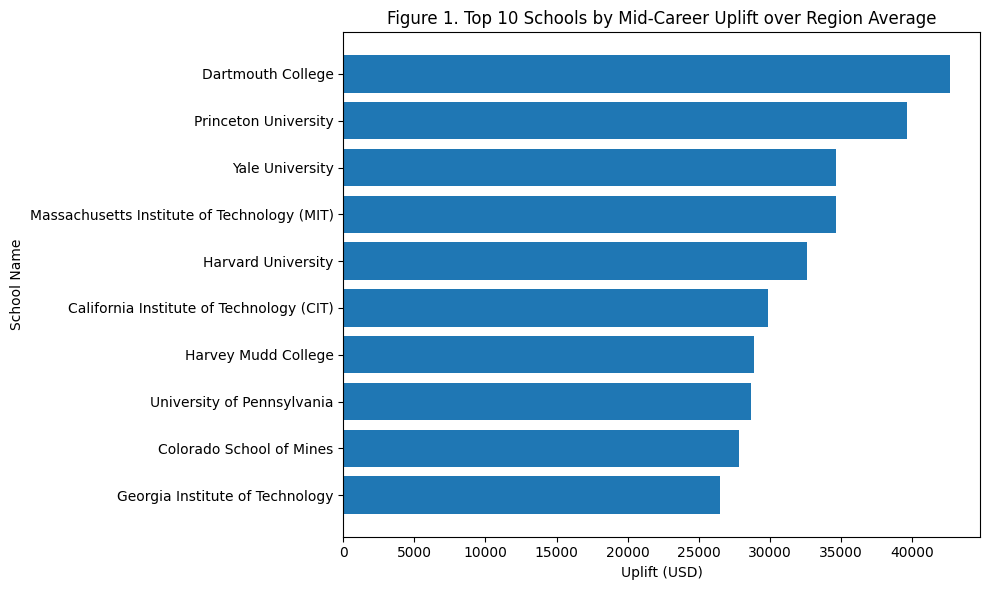

Caption: Mid‑career salary minus **regional average** mid‑career salary (higher is better).


In [21]:
top10 = df.sort_values('Uplift_MidCareer', ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.barh(top10['School_Name'][::-1], top10['Uplift_MidCareer'][::-1])
plt.title('Figure 1. Top 10 Schools by Mid‑Career Uplift over Region Average')
plt.xlabel('Uplift (USD)')
plt.ylabel('School Name')
plt.tight_layout()
plt.show()
print('Caption: Mid‑career salary minus **regional average** mid‑career salary (higher is better).')

## 7) Region × School Type — Group Means & Plot

Title: Group means of Starting Salary by Region × School Type
Caption: Interaction-like differences across region and school type.


School_Type,Engineering,Ivy League,Liberal Arts,Party,State
Region,,,,,
California,"73,650.00",NaN,"47,333.33","50,500.00","48,304.76"
Midwestern,"55,900.00",NaN,"43,237.50","46,525.00","43,190.00"
Northeastern,"60,355.56","60,475.00","47,272.00","45,400.00","44,148.00"
Southern,"52,666.67",NaN,"47,725.00","44,918.18","43,372.00"
Western,"54,550.00",NaN,"41,357.14","47,400.00","43,996.55"


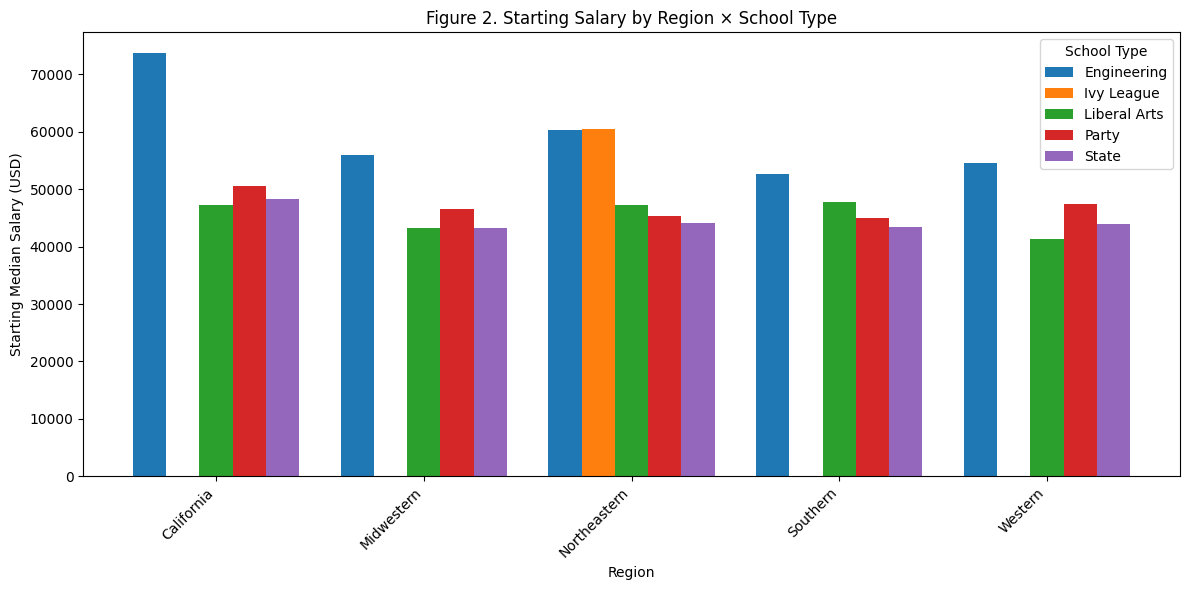

Caption: Clustered bars highlight joint differences by region and type.


In [22]:
target = 'Starting_Median_Salary'
if all(c in df.columns for c in ['Region','School_Type',target]):
    pivot = df.pivot_table(values=target, index='Region', columns='School_Type', aggfunc='mean')
    print('Title: Group means of Starting Salary by Region × School Type')
    print('Caption: Interaction-like differences across region and school type.')
    display(pivot)

    # Clustered bars (matplotlib)
    regions = pivot.index.tolist()
    types = pivot.columns.tolist()
    x = np.arange(len(regions))
    width = 0.8 / max(1, len(types))

    plt.figure(figsize=(12, 6))
    for i, t in enumerate(types):
        plt.bar(x + i*width, pivot[t].values, width=width, label=str(t))
    plt.xticks(x + (len(types)-1)*width/2, regions, rotation=45, ha='right')
    plt.title('Figure 2. Starting Salary by Region × School Type')
    plt.xlabel('Region')
    plt.ylabel('Starting Median Salary (USD)')
    plt.legend(title='School Type')
    plt.tight_layout()
    plt.show()
    print('Caption: Clustered bars highlight joint differences by region and type.')
else:
    print('Required columns missing for Region × School Type analysis.')

## 8) Correlation & Interaction Model

Title: Correlation (Starting vs Mid-Career)
Caption: Pearson correlation shows basic linear association.


,Starting_Median_Salary,Mid_Career_Median_Salary
Starting_Median_Salary,1.00,0.89
Mid_Career_Median_Salary,0.89,1.00


Title: Interaction linear model summary
Caption: OLS with Starting + Region + Type + Region×Type; higher R² indicates better fit.
{'intercept': -25612.662506612163, 'r2': 0.8707301037332652, 'n': 268}


,feature,coef
6,Type_Liberal Arts,"21,590.38"
7,Type_Party,"19,055.44"
8,Type_State,"17,070.14"
4,Region_Western,"15,610.75"
3,Region_Southern,"13,498.20"
2,Region_Northeastern,"12,602.25"
1,Region_Midwestern,"8,795.86"
5,Type_Ivy League,"5,759.06"
13,Region_Northeastern*Type_Ivy League,"5,759.06"
0,Starting_Median_Salary,2.01


,feature,coef
14,Region_Northeastern*Type_Liberal Arts,"-10,337.57"
11,Region_Midwestern*Type_Party,"-11,451.99"
12,Region_Midwestern*Type_State,"-11,865.89"
15,Region_Northeastern*Type_Party,"-11,945.97"
16,Region_Northeastern*Type_State,"-11,998.86"
19,Region_Southern*Type_Party,"-13,545.70"
20,Region_Southern*Type_State,"-14,738.25"
24,Region_Western*Type_State,"-18,533.00"
22,Region_Western*Type_Liberal Arts,"-18,987.67"
23,Region_Western*Type_Party,"-20,276.55"


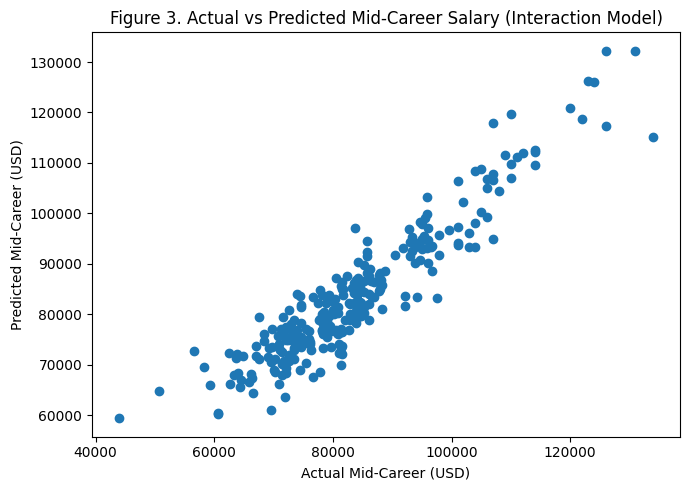

Caption: Points closer to the diagonal imply better predictions; R² printed above.


In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Simple correlation (college-level)
cols = ['Starting_Median_Salary','Mid_Career_Median_Salary']
corr = df[cols].corr()
print('Title: Correlation (Starting vs Mid-Career)')
print('Caption: Pearson correlation shows basic linear association.')
display(corr)

# Interaction model: Mid_Career ~ Starting + Region + Type + Region×Type
y_col = 'Mid_Career_Median_Salary'
X_cols = ['Starting_Median_Salary', 'Region', 'School_Type']
if all(c in df.columns for c in X_cols+[y_col]):
    tmp = df[['Starting_Median_Salary','Region','School_Type', y_col]].dropna()

    # One-hot encode Region and School_Type
    d_region = pd.get_dummies(tmp['Region'], prefix='Region', drop_first=True)
    d_type   = pd.get_dummies(tmp['School_Type'], prefix='Type', drop_first=True)

    # Build interaction terms
    inter = {}
    for rc in d_region.columns:
        for tc in d_type.columns:
            inter[f'{rc}*{tc}'] = d_region[rc].values * d_type[tc].values
    inter_df = pd.DataFrame(inter, index=tmp.index)

    X = pd.concat([tmp[['Starting_Median_Salary']], d_region, d_type, inter_df], axis=1)
    y = tmp[y_col].values

    model = LinearRegression().fit(X, y)
    y_pred = model.predict(X)
    r2 = r2_score(y, y_pred)

    coef_tbl = pd.DataFrame({'feature': X.columns, 'coef': model.coef_}).sort_values('coef', ascending=False)
    print('Title: Interaction linear model summary')
    print('Caption: OLS with Starting + Region + Type + Region×Type; higher R² indicates better fit.')
    print({'intercept': float(model.intercept_), 'r2': float(r2), 'n': int(len(X))})
    display(coef_tbl.head(10))
    display(coef_tbl.tail(10))

    # Actual vs Predicted
    plt.figure(figsize=(7,5))
    plt.scatter(y, y_pred)
    plt.title('Figure 3. Actual vs Predicted Mid‑Career Salary (Interaction Model)')
    plt.xlabel('Actual Mid‑Career (USD)')
    plt.ylabel('Predicted Mid‑Career (USD)')
    plt.tight_layout()
    plt.show()
    print('Caption: Points closer to the diagonal imply better predictions; R² printed above.')
else:
    print('Required columns missing for interaction model.')

## 9) Uplift Distribution

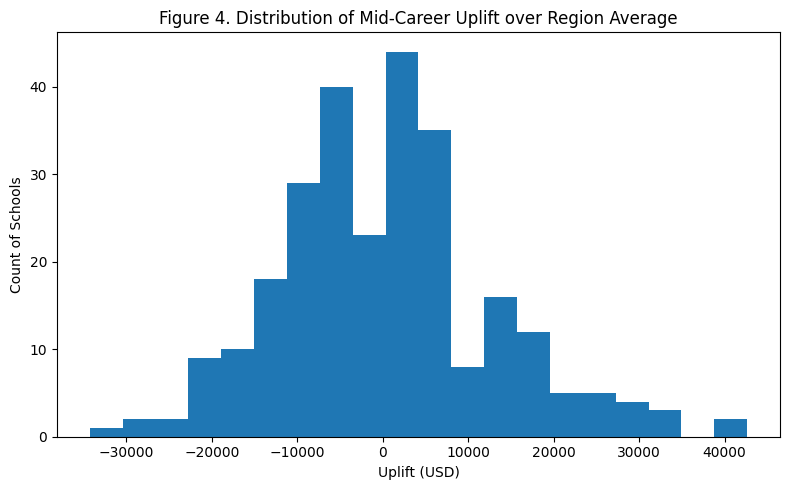

Caption: Spread of schools above/below their region’s baseline.


In [24]:
plt.figure(figsize=(8,5))
vals = df['Uplift_MidCareer'].dropna().values
plt.hist(vals, bins=20)
plt.title('Figure 4. Distribution of Mid‑Career Uplift over Region Average')
plt.xlabel('Uplift (USD)')
plt.ylabel('Count of Schools')
plt.tight_layout()
plt.show()
print('Caption: Spread of schools above/below their region’s baseline.')

## 10) Save Artifacts

In [25]:
# Save cleaned master table & key outputs
df.to_csv('college_salary_master_with_regionavg.csv', index=False)
print('Title: Saved outputs')
print('Caption: Wrote master table to college_salary_master_with_regionavg.csv')

Title: Saved outputs
Caption: Wrote master table to college_salary_master_with_regionavg.csv


## 11) Key Insights & Conclusion

- **Region-adjusted performance (Uplift):** Several schools materially exceed their region’s mid‑career average; others underperform.  
- **Region × School Type effects:** Starting salaries differ jointly by Region and School Type; some combinations show pronounced advantages.  
- **Predictive model:** Starting salary is a strong predictor of mid‑career pay, and **regional context + type interactions** add explanatory power.  
- **Practical use:** In downturns, regionally adjusted signals help identify programs that sustain strong outcomes **relative to local conditions**.

> Limitations: No major/industry variables; region labels must align across files; causal claims are not warranted from observational data.
